# 04 · Irradiancia global horizontal (GHI) desde GOES
Método de **índice de nubosidad** (tipo Heliosat-2; Rigollier et al., 2004):

1. $\rho^* = \rho / \cos z$: la reflectancia del canal 2 se normaliza por la altura del sol.
2. Se estiman dos referencias:
   - $\rho_{desp}$: percentil 5 de $\rho^*$ por píxel y hora del día. Es la superficie sin nubes.
   - $\rho_{nube}$: percentil 99 de todo el dominio. Es la nube densa.
3. Índice de nubosidad: $n = (\rho^* - \rho_{desp}) / (\rho_{nube} - \rho_{desp})$.
4. Índice de cielo despejado: $K_c = f(n)$.
5. $GHI = K_c \times GHI_{despejado}$, con el modelo **Ineichen** y la **altitud del DEM**.

**Salida:** `datos/procesados/irradiancia_YYYYMM.nc` con `kc`, `ghi` y `ghi_despejado` en la malla de ~2 km.

In [1]:
# ▶ CELDA DE PREPARACIÓN — ejecútala siempre de primera
import os, sys, subprocess
from pathlib import Path

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    # En Colab los archivos se guardan en tu Google Drive para no perderlos
    from google.colab import drive
    drive.mount("/content/drive")
    CARPETA = Path("/content/drive/MyDrive/scm_magdalena")   # cámbiala si quieres
    CARPETA.mkdir(parents=True, exist_ok=True)
    os.chdir(CARPETA)
    PAQUETES = ["numpy", "scipy", "pandas", "xarray", "dask", "netCDF4", "h5netcdf", "s3fs", "pyproj", "shapely", "geopandas", "rasterio", "pvlib", "pydataxm", "libpysal", "esda", "matplotlib"]
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *PAQUETES], check=True)

if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())
print("Carpeta de trabajo:", os.getcwd())
assert Path("config.py").exists(), "No encuentro config.py: ejecuta primero el notebook 00 en esta misma carpeta"

Carpeta de trabajo: c:\Users\User\Desktop\Unal\Analisis Geoespacial\notebooks_scm_magdalena


In [2]:
import numpy as np
import pandas as pd
import xarray as xr
import rasterio
import pvlib
import geopandas as gpd
import matplotlib.pyplot as plt
import config as C
from utils import cos_zenit, indice_nubosidad, indice_cielo_despejado, a_malla_regular, malla_regular

with rasterio.open(C.PROC / "dem_2km.tif") as src:
    altitud = src.read(1)
lat_r, lon_r = malla_regular(C.DOM_ANALISIS, C.RES_MALLA)
print("Malla de análisis:", altitud.shape)

Malla de análisis: (150, 90)


## 1. Irradiancia de cielo despejado (Ineichen–Perez con altitud)

In [3]:
def ghi_despejado(tiempos, lat2d, lon2d, altitud):
    cz = cos_zenit(tiempos, lat2d, lon2d)
    zen = np.degrees(np.arccos(np.clip(cz, -1, 1)))
    am_rel = pvlib.atmosphere.get_relative_airmass(zen)
    presion = pvlib.atmosphere.alt2pres(np.nan_to_num(altitud, nan=0.0))[None]
    am_abs = pvlib.atmosphere.get_absolute_airmass(am_rel, presion)
    la0, la1, lo0, lo1 = C.DOM_ANALISIS
    idx = pd.DatetimeIndex(tiempos)
    tl = pvlib.clearsky.lookup_linke_turbidity(idx, (la0 + la1) / 2, (lo0 + lo1) / 2).values
    dni_extra = pvlib.irradiance.get_extra_radiation(idx).values
    cs = pvlib.clearsky.ineichen(zen, am_abs, tl[:, None, None],
                                 altitude=np.nan_to_num(altitud, nan=0.0)[None],
                                 dni_extra=dni_extra[:, None, None])
    return np.where(zen < 90, cs["ghi"], 0.0), zen

## 2. Procesamiento mes a mes

In [4]:
def procesar_mes(archivos):
    ds = xr.open_mfdataset(archivos, combine="nested", concat_dim="time", coords="minimal", compat="override")
    lat, lon = ds["lat"].values, ds["lon"].values
    if lat.ndim == 3:
        lat, lon = lat[0], lon[0]
    t = ds["time"].values
    rho = ds["reflectancia"].values
    cz = cos_zenit(t, lat, lon)
    zen = np.degrees(np.arccos(cz))
    rho_n = np.where(zen < C.ZENIT_MAX, rho / np.maximum(cz, 0.05), np.nan)

    horas = pd.DatetimeIndex(t).hour
    rho_desp = np.full_like(rho_n, np.nan)
    for h in np.unique(horas):
        sel = horas == h
        rho_desp[sel] = np.nanpercentile(rho_n[sel], C.PERCENTIL_CIELO_DESPEJADO, axis=0)
    rho_nube = np.nanpercentile(rho_n, C.PERCENTIL_NUBE)
    kc_goes = indice_cielo_despejado(indice_nubosidad(rho_n, rho_desp, rho_nube))

    LO, LA = np.meshgrid(lon_r, lat_r)
    kc = np.stack([a_malla_regular(k, lat, lon, C.DOM_ANALISIS, C.RES_MALLA)[0] for k in kc_goes])
    gcs, zen_r = ghi_despejado(t, LA, LO, altitud)
    kc = np.where(zen_r < C.ZENIT_MAX, kc, np.nan)
    return xr.Dataset(
        {"kc": (("time", "lat", "lon"), kc.astype("float32")),
         "ghi": (("time", "lat", "lon"), (kc * gcs).astype("float32")),
         "ghi_despejado": (("time", "lat", "lon"), gcs.astype("float32"))},
        coords={"time": t, "lat": lat_r, "lon": lon_r},
        attrs={"metodo": "Heliosat-2 simplificado + Ineichen con altitud del DEM"})


archivos = sorted((C.RAW / "vis").glob("vis_*.nc"))
for m in sorted({a.stem[4:10] for a in archivos}):
    destino = C.PROC / f"irradiancia_{m}.nc"
    if destino.exists():
        print("ya existe", destino.name); continue
    ds = procesar_mes([a for a in archivos if a.stem[4:10] == m])
    ds.to_netcdf(destino, encoding={v: {"zlib": True} for v in ds.data_vars})
    print("listo", destino.name)

c:\Users\User\miniforge3\Lib\site-packages\numpy\lib\_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,


listo irradiancia_202410.nc


c:\Users\User\miniforge3\Lib\site-packages\pvlib\clearsky.py:132: RuntimeWarning: divide by zero encountered in divide
  bnci_2 = ((1 - (0.1 - 0.2*np.exp(-tl))/(0.1 + 0.882/fh1)) /


## 3. Revisión visual

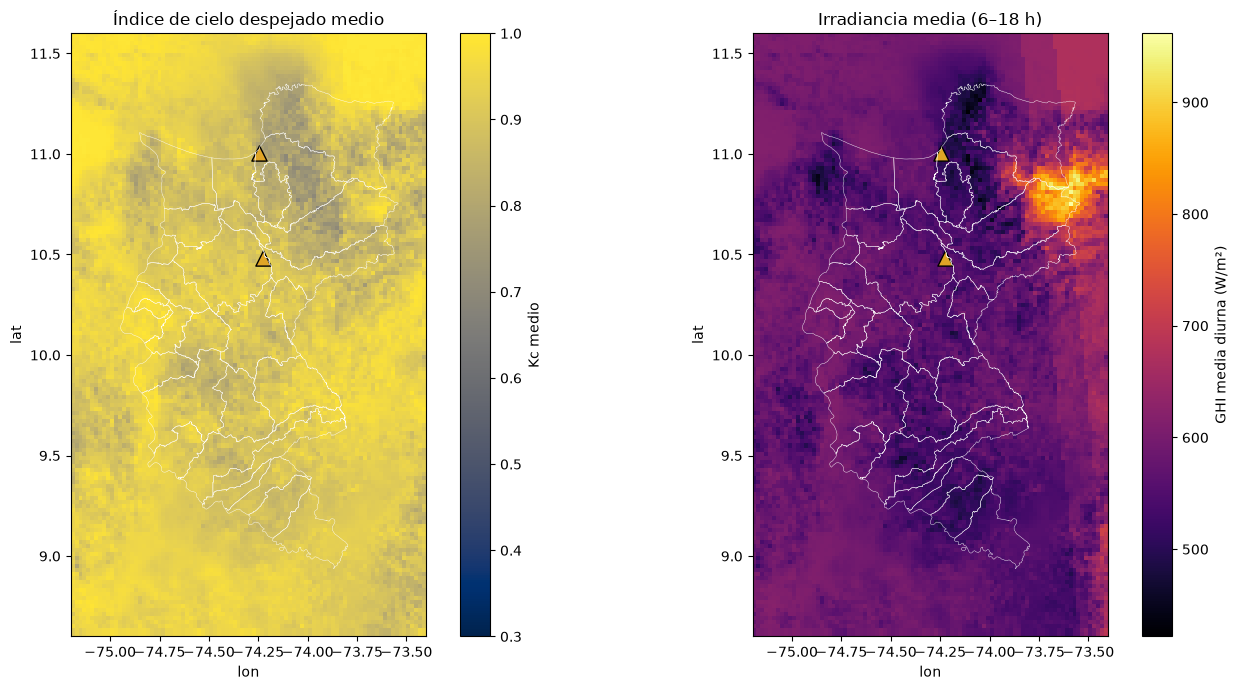

In [5]:
irr = xr.open_mfdataset(sorted(C.PROC.glob("irradiancia_*.nc")))
mpios = gpd.read_file(C.PROC / "municipios.gpkg")
parques = gpd.read_file(C.PROC / "parques.gpkg")

fig, axs = plt.subplots(1, 2, figsize=(14, 7))
irr["kc"].mean("time").plot(ax=axs[0], cmap="cividis", vmin=0.3, vmax=1.0, cbar_kwargs={"label": "Kc medio"})
(irr["ghi"].mean("time")).plot(ax=axs[1], cmap="inferno", cbar_kwargs={"label": "GHI media diurna (W/m²)"})
for ax in axs:
    mpios.boundary.plot(ax=ax, color="w", linewidth=0.3)
    parques.plot(ax=ax, color="#E0A526", edgecolor="k", marker="^", markersize=120)
axs[0].set_title("Índice de cielo despejado medio"); axs[1].set_title("Irradiancia media (6–18 h)")
plt.tight_layout(); plt.savefig(C.OUT / "mapa_irradiancia_media.png", dpi=150); plt.show()

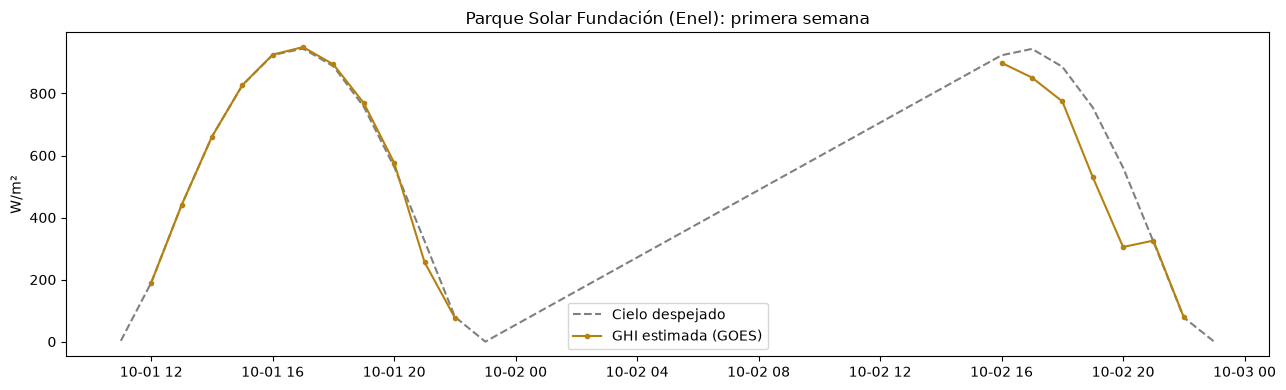

In [6]:
# Serie de una semana en el primer parque: GHI estimada vs. cielo despejado
p = parques.iloc[0]
s = irr.sel(lat=p.lat, lon=p.lon, method="nearest").to_dataframe()
s = s.iloc[:13 * 7]
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(s.index, s["ghi_despejado"], "--", color="0.5", label="Cielo despejado")
ax.plot(s.index, s["ghi"], "o-", ms=3, color="#B5810F", label="GHI estimada (GOES)")
ax.set_ylabel("W/m²"); ax.set_title(f"{p['nombre']}: primera semana"); ax.legend()
plt.tight_layout(); plt.show()

**¿Qué revisar?**
- El Kc medio debería estar entre ~0,4 y 0,9.
- La Sierra Nevada debería verse más nublada que la franja costera seca.
- En días despejados la GHI debe acercarse a la curva de cielo despejado.

✅ Sigue con el notebook **05**.